# <b>Combinatorial Optimization with QAOA: Max-Cut </b>
**Author:** Benjamin Tirado

<a id="goal"></a>
<div class="alert alert-block alert-success">
    
<b>Goal of this notebook: </b> Solve the **Max-Cut problem** on a small graph using the **Quantum Approximate Optimization Algorithm (QAOA)**. We will translate a combinatorial problem into a **cost Hamiltonian**, build the QAOA circuit from alternating **cost** and **mixer** layers, optimize its parameters with a classical routine, and sample the result to read out a good partition — checking it against a brute-force solution. By the end you will have a reusable QAOA template that you can point at harder, more realistic optimization problems.
</div>

# <b>Table of Contents</b>

* [Background](#background)
* [Pre-requisites](#prereq)
* [Defining the Problem: Max-Cut on a Graph](#problem)
* [From Cost Function to Hamiltonian](#hamiltonian)
* [Building the QAOA Circuit](#circuit)
* [Optimizing the Parameters](#optimize)
* [Sampling and Reading the Solution](#sample)
* [Results and Evaluation](#res)
* [Moving forward](#move)
* [Useful resources](#use)

## <b>Background </b> <a id="background"></a>

Many important problems in logistics, finance, scheduling, and network design are **combinatorial optimization** problems: choose the best option out of an enormous, discrete set of possibilities. Because the number of candidate solutions grows exponentially with problem size, exact classical methods struggle as problems get large, and much of computer science is devoted to good approximate methods.

Quantum computers offer a different angle of attack. The **Quantum Approximate Optimization Algorithm (QAOA)**, introduced by Farhi, Goldstone and Gutmann in 2014, is a hybrid quantum-classical algorithm designed to find good approximate solutions to such problems. It has since become one of the most studied quantum optimization methods, and a decade later it sits at the heart of utility-scale demonstrations on IBM hardware (for example the error-suppressed pipeline of Sachdeva et al., 2024, which tackled nontrivial binary optimization at the 100+ qubit scale).

The idea behind QAOA is elegant. Any problem where we want to *minimize a cost* can be encoded into a **cost Hamiltonian** $\hat{H}_C$, built so that its lowest-energy state corresponds to the best solution. QAOA prepares a trial state by alternating two ingredients:

$$
|\psi(\vec{\gamma}, \vec{\beta})\rangle = \prod_{k=1}^{p} e^{-i\beta_k \hat{H}_M}\, e^{-i\gamma_k \hat{H}_C}\; |+\rangle^{\otimes n},
$$

where $\hat{H}_C$ is the **cost** Hamiltonian (it rewards good solutions), $\hat{H}_M = \sum_i X_i$ is the **mixer** (it explores different candidate solutions), and the integer $p$ is the number of **layers** (also called the QAOA depth). The angles $\vec{\gamma}$ and $\vec{\beta}$ are tuned by a classical optimizer to minimize the expected cost. As $p$ grows, QAOA can represent better and better solutions, at the price of deeper circuits.

As our teaching problem we use **Max-Cut**, the standard entry point to QAOA: it maps onto a cost Hamiltonian in the simplest possible way, and on small graphs we can check the quantum answer against brute force.

# <b>Pre-requisites </b> <a id="prereq"></a>
For starters, make sure you have installed the Qiskit SDK and its supporting modules: `qiskit_aer` (for noiseless simulations) and `qiskit_ibm_runtime` (for real-hardware experiments), as well as the visualization package `qiskit[visualization]`. We use `qiskit.circuit.library.QAOAAnsatz` to build the QAOA circuit, the built-in `StatevectorEstimator` and `StatevectorSampler` primitives to evaluate and sample it, and `scipy.optimize` for the classical parameter optimization. Graphs are handled with `rustworkx`, Qiskit's companion graph library.

For run our circiuts codes on real IMB Quantum hardware.

In [ ]:
%pip install -q qiskit-ibm-runtime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 24.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 412.6/412.6 kB 15.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 120.7/120.7 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.7/95.7 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 65.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 113.3/113.3 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 234.2/234.2 kB 15.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.8/76.8 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.0/131.0 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 55.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 541.5/541.5 kB 19.4 MB/s eta 0:00:00


In [ ]:
from google.colab import userdata
from qiskit_ibm_runtime import QiskitRuntimeService

api_key = userdata.get("IBM_QUANTUM_API_KEY")

service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    token=api_key,
)

print("Successfully connected to IBM Quantum!")

qiskit_runtime_service._discover_account:WARNING:2026-10-14 05:52:15,314: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-10-14 05:52:18,246: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.


Successfully connected to IBM Quantum!


In [ ]:
# List available quantum backends
backends = service.backends()

print("Available quantum backends:")
for backend in backends:
    print(
        f"Name: {backend.name}, "
        f"Operational: {backend.status().operational}, "
        f"Pending jobs: {backend.status().pending_jobs}"
    )

qiskit_runtime_service.backends:WARNING:2026-10-14 05:53:25,559: Loading instance: open-instance, plan: open


Available quantum backends:
Name: ibm_fez, Operational: True, Pending jobs: 4
Name: ibm_kingston, Operational: True, Pending jobs: 1
Name: ibm_marrakesh, Operational: True, Pending jobs: 3


In [ ]:
backend = service.backend("ibm_kingston")

print("Selected backend:", backend.name)
print("Number of qubits:", backend.num_qubits)
print("Operational:", backend.status().operational)
print("Pending jobs:", backend.status().pending_jobs)

qiskit_runtime_service.backends:WARNING:2026-10-14 05:54:27,925: Using instance: open-instance, plan: open


Selected backend: ibm_kingston
Number of qubits: 156
Operational: True
Pending jobs: 1


In [ ]:
from qiskit import QuantumCircuit
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import SamplerV2

# 1. Create a two-qubit Bell circuit
qc = QuantumCircuit(2, 2)
qc.h(0)
qc.cx(0, 1)
qc.measure([0, 1], [0, 1])

print("Original circuit:")
print(qc.draw())

# 2. Compile for the selected real quantum computer
pm = generate_preset_pass_manager(
    backend=backend,
    optimization_level=1
)
isa_circuit = pm.run(qc)

print("Circuit compiled for:", backend.name)

# 3. Submit to real IBM quantum hardware
sampler = SamplerV2(mode=backend)
job = sampler.run([isa_circuit], shots=256)

print("Job submitted!")
print("Job ID:", job.job_id())

# 4. Retrieve the measurement results
result = job.result()
counts = result[0].data.c.get_counts()

print("\nHardware measurement counts:")
print(counts)

Original circuit:
     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 
Circuit compiled for: ibm_kingston


/tmp/ipykernel_2452/3334453004.py:24: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = SamplerV2(mode=backend)


Job submitted!
Job ID: db7hinaraffc73faipbg

Hardware measurement counts:
{'00': 85, '01': 30, '11': 119, '10': 22}


In [ ]:
from qiskit import QuantumCircuit

circuits = [
    (name, obj)
    for name, obj in globals().copy().items()
    if isinstance(obj, QuantumCircuit)
]

if circuits:
    for name, circuit in circuits:
        print(
            f"Variable: {name} | "
            f"Qubits: {circuit.num_qubits} | "
            f"Parameters: {circuit.num_parameters} | "
            f"Depth: {circuit.depth()}"
        )
else:
    print("No quantum circuits are currently defined.")

Variable: qc | Qubits: 2 | Parameters: 0 | Depth: 3
Variable: isa_circuit | Qubits: 156 | Parameters: 0 | Depth: 8


In [ ]:
%pip install qiskit qiskit_aer qiskit_ibm_runtime qiskit[visualization] rustworkx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 72.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 95.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 83.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 89.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 412.6/412.6 kB 33.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 120.7/120.7 kB 10.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.7/95.7 kB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 12.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 113.3/113.3 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 234.2/234.2 kB 19.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.8/76.8 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.0/13

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import rustworkx as rx
from rustworkx.visualization import mpl_draw as draw_graph
from itertools import product

from qiskit.quantum_info import SparsePauliOp
from qiskit.circuit.library import QAOAAnsatz
from qiskit.primitives import StatevectorEstimator, StatevectorSampler
from scipy.optimize import minimize

# <b>Defining the Problem: Max-Cut on a Graph </b> <a id="problem"></a>
The **Max-Cut** problem is easy to state. Given a graph of nodes connected by edges, split the nodes into **two groups** so that the number of edges running *between* the groups (the edges we "cut") is as large as possible.

We describe a partition by assigning each node a label $x_i \in \{0, 1\}$ — which side of the cut it is on. An edge $(i, j)$ is cut exactly when its two endpoints have different labels. The number of cut edges is therefore

$$
C(\vec{x}) = \sum_{(i,j)\in E} \big[\, x_i \ne x_j \,\big],
$$

and Max-Cut asks us to maximize this over all $2^n$ possible labellings. Let us build a small graph to work with — five nodes, chosen so we can still check every possibility by hand.

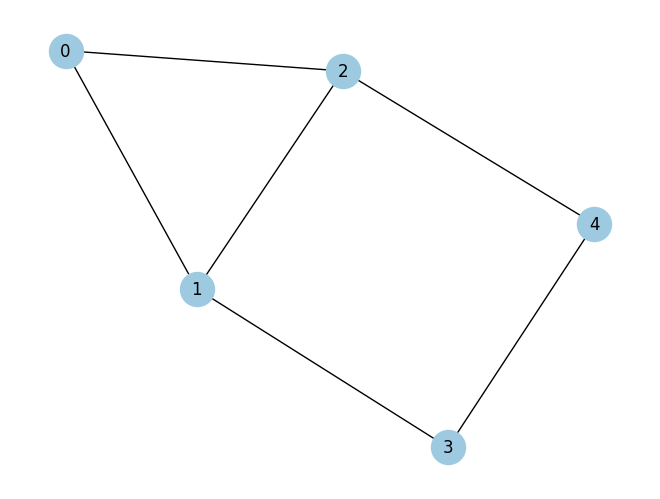

In [ ]:
# Build a small 5-node graph
num_nodes = 5
edges = [(0, 1), (0, 2), (1, 2), (1, 3), (2, 4), (3, 4)]

graph = rx.PyGraph()
graph.add_nodes_from(range(num_nodes))
graph.add_edges_from([(i, j, 1.0) for i, j in edges])  # weight 1 on every edge

draw_graph(graph, node_size=600, with_labels=True, node_color="#9ecae1")

# <b>From Cost Function to Hamiltonian </b> <a id="hamiltonian"></a>
To run Max-Cut on a quantum computer we translate the cost function into a **cost Hamiltonian** whose ground state encodes the optimal cut. The standard trick is to replace each binary variable $x_i \in \{0,1\}$ by a spin $Z_i \in \{+1, -1\}$ via $x_i = (1 - Z_i)/2$. Substituting this into the Max-Cut objective, each edge $(i,j)$ contributes

$$
\big[\, x_i \ne x_j \,\big] \;\longrightarrow\; \tfrac{1}{2}\big(1 - Z_i Z_j\big).
$$

The term $Z_i Z_j$ equals $+1$ when both endpoints are on the same side (edge not cut) and $-1$ when they differ (edge cut). Because quantum systems naturally settle into **minimum** energy, and we want to **maximize** the cut, we minimize the following cost Hamiltonian, dropping constant offsets:

$$
\hat{H}_C = \sum_{(i,j)\in E} \tfrac{1}{2}\, Z_i Z_j.
$$

Its ground state is the spin configuration — the partition — that cuts the most edges. We build it below as a `SparsePauliOp`, one Pauli-`ZZ` string per edge.

In [ ]:
def maxcut_cost_hamiltonian(num_nodes, edges):
    """Build the Max-Cut cost Hamiltonian sum_(i,j) 0.5 * Z_i Z_j."""
    terms = []
    for i, j in edges:
        pauli = ["I"] * num_nodes
        pauli[i] = "Z"
        pauli[j] = "Z"
        # Qiskit reads Pauli strings right-to-left (qubit 0 is the rightmost char)
        terms.append(("".join(reversed(pauli)), 0.5))
    return SparsePauliOp.from_list(terms)


cost_hamiltonian = maxcut_cost_hamiltonian(num_nodes, edges)
print("Cost Hamiltonian (one ZZ term per edge):")
print(cost_hamiltonian)

Cost Hamiltonian (one ZZ term per edge):
SparsePauliOp(['IIIZZ', 'IIZIZ', 'IIZZI', 'IZIZI', 'ZIZII', 'ZZIII'],
              coeffs=[0.5+0.j, 0.5+0.j, 0.5+0.j, 0.5+0.j, 0.5+0.j, 0.5+0.j])


# <b>Building the QAOA Circuit </b> <a id="circuit"></a>
With the cost Hamiltonian in hand, Qiskit can build the QAOA circuit for us. The `QAOAAnsatz` takes the cost operator and a number of repetitions `reps` (this is the depth $p$) and assembles the alternating pattern automatically:

- it starts every qubit in the equal superposition $|+\rangle$ (all candidate solutions at once),
- applies the **cost layer** $e^{-i\gamma_k \hat{H}_C}$ (which imprints the problem structure), and
- applies the **mixer layer** $e^{-i\beta_k \hat{H}_M}$ with $\hat{H}_M = \sum_i X_i$ (which shuffles amplitude between candidates),

repeating for $p$ layers. This leaves $2p$ free parameters (one $\gamma$ and one $\beta$ per layer) for the optimizer to tune.

We start with the shallowest non-trivial case, $p = 1$, which has just two parameters. We add measurements so we can later sample bitstrings from the circuit.

QAOA depth p = 1
Number of qubits: 5
Number of parameters: 2


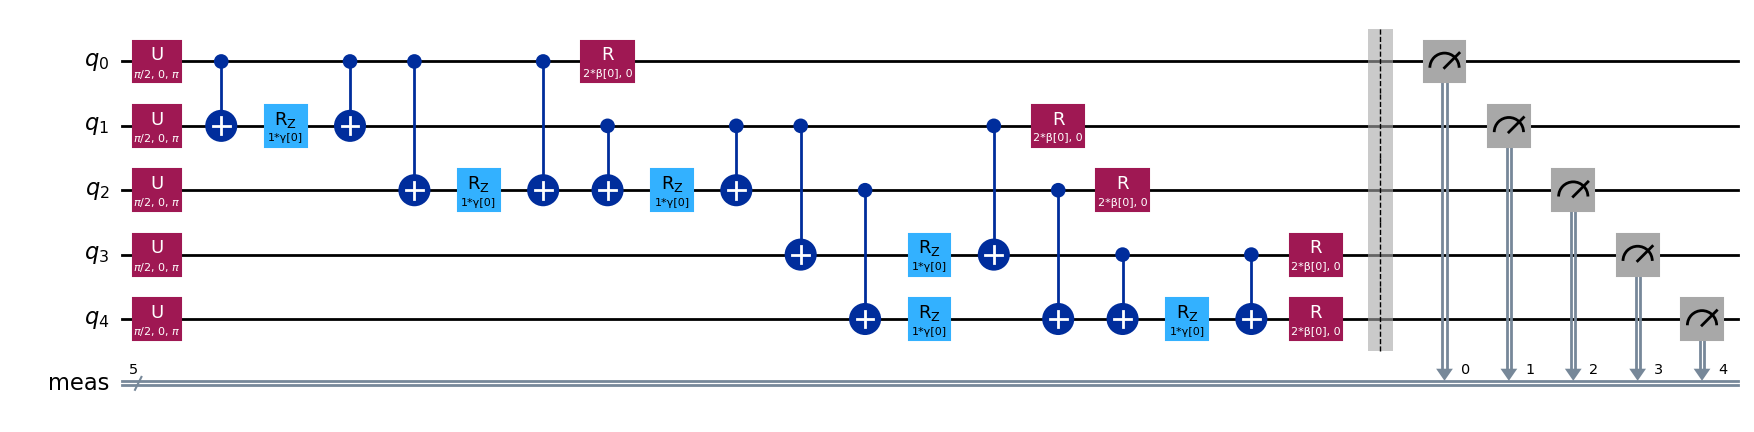

In [ ]:
p = 1  # QAOA depth (number of layers)
ansatz = QAOAAnsatz(cost_operator=cost_hamiltonian, reps=p)
ansatz.measure_all()

print(f"QAOA depth p = {p}")
print("Number of qubits:", ansatz.num_qubits)
print("Number of parameters:", ansatz.num_parameters)
ansatz.decompose(reps=3).draw("mpl", fold=-1)

# <b>Optimizing the Parameters </b> <a id="optimize"></a>
QAOA is a **hybrid** algorithm: the quantum computer prepares the trial state and estimates its energy, while a **classical optimizer** adjusts the angles $(\vec{\gamma}, \vec{\beta})$ to drive that energy down. The quantity we minimize is the expected value of the cost Hamiltonian,

$$
E(\vec{\gamma}, \vec{\beta}) = \langle \psi(\vec{\gamma}, \vec{\beta}) | \hat{H}_C | \psi(\vec{\gamma}, \vec{\beta}) \rangle,
$$

which we evaluate with the `StatevectorEstimator` (exact and noiseless — ideal for learning). We wrap this in a small cost function and hand it to `scipy.optimize.minimize` with the **COBYLA** optimizer, a gradient-free method that copes well with the noisy, non-convex landscapes typical of QAOA.

Note we pass the ansatz *without* its measurements to the Estimator (expectation values are computed from the statevector, not from samples); the measured copy is kept for the sampling step that follows.

In [ ]:
estimator = StatevectorEstimator()

# Estimator needs the circuit without measurements
ansatz_no_meas = QAOAAnsatz(cost_operator=cost_hamiltonian, reps=p)

objective_history = []

def cost_function(params):
    """Expected energy of the cost Hamiltonian for given QAOA angles."""
    pub = (ansatz_no_meas, cost_hamiltonian, params)
    energy = estimator.run([pub]).result()[0].data.evs
    energy = float(energy)
    objective_history.append(energy)
    return energy

# QAOA is sensitive to initialization: a single random start can stall in a poor local minimum.
# Try a few starting points and keep the best run.
rng = np.random.default_rng(42)
result, best_history = None, []
for _ in range(8):
    objective_history.clear()
    initial_params = rng.uniform(0, np.pi, ansatz_no_meas.num_parameters)
    trial = minimize(cost_function, initial_params, method="COBYLA",
                     options={"maxiter": 200})
    if result is None or trial.fun < result.fun:
        result, best_history = trial, list(objective_history)
objective_history = best_history  # convergence curve of the best run

print("Optimization finished.")
print("Optimal parameters:", np.round(result.x, 4))
print(f"Minimum expected energy: {result.fun:.4f}")

Optimization finished.
Optimal parameters: [1.217 0.649]
Minimum expected energy: -1.1101


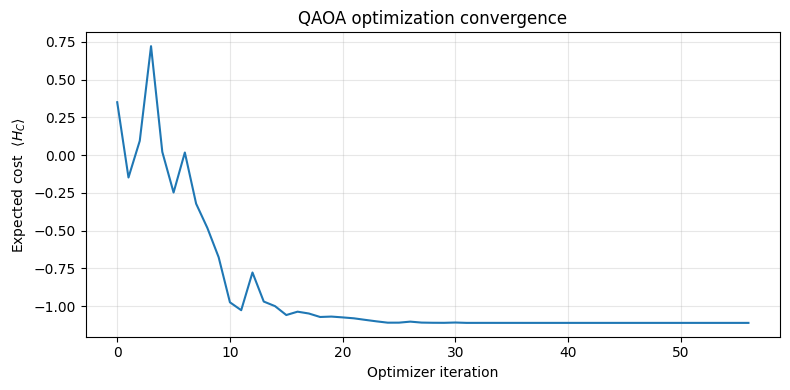

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(objective_history, color="#1f77b4")
plt.xlabel("Optimizer iteration")
plt.ylabel(r"Expected cost  $\langle H_C \rangle$")
plt.title("QAOA optimization convergence")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# <b>Sampling and Reading the Solution </b> <a id="sample"></a>
Minimizing the energy gives us good angles, but the *solution* we care about is a **bitstring** — an actual assignment of nodes to the two sides of the cut. To get it, we bind the optimal parameters into the measured circuit and **sample** it many times with the `StatevectorSampler`. The most frequently observed bitstrings are QAOA's candidate solutions.

For each sampled bitstring we compute how many edges it cuts, and keep the best. On a small graph the optimal partition should dominate the sampled distribution when QAOA has done its job.

In [ ]:
def cut_value(bitstring, edges):
    """Number of edges cut by a given assignment (bitstring)."""
    # bitstring[i] is the side (0 or 1) assigned to node i
    return sum(1 for i, j in edges if bitstring[i] != bitstring[j])


sampler = StatevectorSampler()
best = ansatz.assign_parameters(result.x)
samples = sampler.run([best], shots=4096).result()[0].data.meas.get_counts()

# Convert each measured key (a bit-string) into a per-node assignment.
# Qiskit bitstrings are little-endian: the rightmost char is qubit 0.
def key_to_assignment(key, num_nodes):
    bits = key.replace(" ", "")[::-1]  # reverse -> index 0 is node 0
    return [int(bits[i]) for i in range(num_nodes)]

scored = []
for key, count in samples.items():
    assignment = key_to_assignment(key, num_nodes)
    scored.append((assignment, count, cut_value(assignment, edges)))

# Sort by how often each bitstring appeared
scored.sort(key=lambda t: t[1], reverse=True)
print("Most sampled bitstrings (assignment, count, cut value):")
for assignment, count, cut in scored[:5]:
    print(f"  {assignment}   count={count:5d}   cut={cut}")

Most sampled bitstrings (assignment, count, cut value):
  [1, 1, 0, 0, 1]   count=  447   cut=5
  [1, 0, 1, 1, 0]   count=  436   cut=5
  [0, 1, 0, 0, 1]   count=  420   cut=5
  [0, 0, 1, 1, 0]   count=  407   cut=5
  [0, 1, 1, 0, 0]   count=  282   cut=4


# <b>Results and Evaluation </b> <a id="res"></a>
Because the graph is small, we can **brute-force** the true optimum: enumerate all $2^n$ partitions, compute each cut value, and find the maximum. Comparing QAOA's best sampled cut to this exact optimum tells us how well the algorithm did.

A common summary metric is the **approximation ratio**, the ratio of the cut QAOA found to the true optimal cut. A ratio of $1.0$ means QAOA recovered an optimal partition. At $p = 1$ on a simple graph you should already get close; one of the first things you will explore in the challenge is how this ratio improves as the depth $p$ grows.

Brute-force optimal cut : 5
QAOA best sampled cut   : 5
Approximation ratio     : 1.000


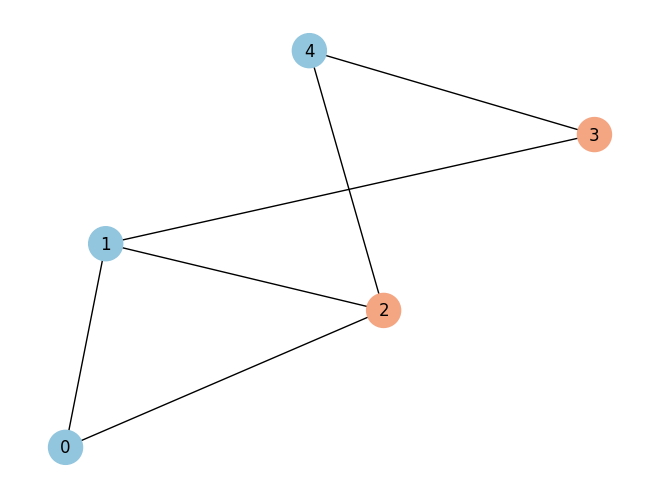

In [ ]:
# Brute-force optimum
best_cut, best_assignments = 0, []
for bits in product([0, 1], repeat=num_nodes):
    c = cut_value(bits, edges)
    if c > best_cut:
        best_cut, best_assignments = c, [bits]
    elif c == best_cut:
        best_assignments.append(bits)

qaoa_best = max(scored, key=lambda t: t[2])
qaoa_cut = qaoa_best[2]
approx_ratio = qaoa_cut / best_cut

print(f"Brute-force optimal cut : {best_cut}")
print(f"QAOA best sampled cut   : {qaoa_cut}")
print(f"Approximation ratio     : {approx_ratio:.3f}")

# Visualize the QAOA partition
colors = ["#f4a582" if b == 0 else "#92c5de" for b in qaoa_best[0]]
draw_graph(graph, node_size=600, with_labels=True, node_color=colors)

# <b>Moving forward </b> <a id="move"></a>
This notebook walked through the full QAOA workflow on a deliberately tiny, unweighted Max-Cut instance: encode the cost, build the alternating circuit, optimize two angles, sample, and check against brute force. The hackathon challenge takes QAOA out of the toy graph and points it at a **real-world optimization problem** — and, crucially, at problems with **constraints**, which is where encoding becomes an art.

The three levels below are open-ended: they state a target, not a recipe. Choosing the encoding, the depth, the optimizer, and (from the intermediate level) the overall algorithmic approach is part of the challenge.

### <b>The challenge problem — portfolio selection</b>
The challenge centres on a **portfolio-selection** problem: from a universe of assets, choose a subset that maximizes expected return while penalizing risk, subject to a **budget constraint** (for example, pick exactly $K$ assets). This problem is a natural fit for QAOA — it maps to a cost Hamiltonian just like Max-Cut — but it adds the essential ingredient of a constraint, which you must fold into the encoding (typically as a penalty term). Small instances can still be checked by brute force, so you can measure how well you are doing.

### <b>Getting Started — Beginner</b>
Set up a small portfolio-selection instance, encode it as a cost Hamiltonian (objective **plus** a budget-constraint penalty), and solve it with QAOA following the workflow from this notebook. Then study the two knobs that matter most at this level: how the **approximation ratio improves with QAOA depth $p$**, and how the **penalty strength** on the constraint affects whether the solutions QAOA returns are actually feasible. Verify against a brute-force optimum.

### <b>Intermediate — Choose Your Approach</b>
Scale to a larger or more tightly constrained instance and commit to a strategy. This level **forks**, and part of the task is to justify which path you take and compare it against a sensible classical baseline:

- **Variational / QAOA route.** Push QAOA harder: warm-starting from a classical relaxation, constraint-preserving or custom mixers that keep the search inside the feasible set, better classical optimizers, or smarter parameter initialization.
- **Quantum machine learning route.** Treat the problem through a learning lens: for example, a variational model trained to produce high-quality (feasible) solutions, or a QML approach to the underlying selection/classification structure.

### <b>Advanced — Push Toward Utility Scale</b>
Move toward the regime where naive encodings and shallow circuits stop working. Explore what it takes to get good solutions as the problem grows: confronting **trainability** issues (barren plateaus), **higher-order terms or heavier constraints**, and the **error suppression and hardware-aware compilation** that utility-scale optimization demands. The inspiration here is the integrated, error-suppressed pipelines that have pushed gate-model optimization to the 100+ qubit scale — how close can you get to a robust, scalable solver?

### <b>Running on real hardware</b>
Whichever level you tackle, moving from the `StatevectorEstimator` to a real IBM Quantum device (for example the least busy one on your account, `service.least_busy(operational=True, simulator=False)`) changes the game. The two-qubit cost terms must be mapped onto the heavy-hex connectivity, and terms between non-adjacent qubits force the transpiler to insert SWAPs that deepen the circuit — SWAP networks and commuting-gate routing become valuable. Finite shots and gate noise also blur the sampled distribution, so error suppression and mitigation (dynamical decoupling, twirling, and more) become part of getting a trustworthy answer.

# <b>Useful resources </b> <a id="use"></a>

The following resources may be useful when extending this introductory QAOA example toward the full challenge.

### <b>QAOA and quantum optimization in Qiskit </b>

- [Quantum approximate optimization algorithm (IBM tutorial)](https://quantum.cloud.ibm.com/docs/tutorials/quantum-approximate-optimization-algorithm)  
  End-to-end QAOA for Max-Cut, from a small graph to a 100-node utility-scale problem on real hardware — the closest reference to this notebook.

- [Advanced techniques for QAOA](https://quantum.cloud.ibm.com/docs/tutorials/advanced-techniques-for-qaoa)  
  SWAP networks, commuting-gate routing, and depth reduction for QAOA on hardware — relevant to the advanced level.

- [QAOAAnsatz documentation](https://quantum.cloud.ibm.com/docs/api/qiskit/qiskit.circuit.library.QAOAAnsatz)  
  Reference page for the QAOA circuit class used here, including the mixer and initial-state options.

- [Qiskit Optimization documentation](https://qiskit-community.github.io/qiskit-optimization/)  
  Tools for building `QuadraticProgram`s, encoding constraints, and converting problems to Ising Hamiltonians.

- [Max-Cut and TSP tutorial](https://qiskit-community.github.io/qiskit-optimization/tutorials/06_examples_max_cut_and_tsp.html)  
  Shows the QUBO-to-Ising conversion and application classes for standard optimization problems.

- [Portfolio optimization tutorial](https://qiskit-community.github.io/qiskit-finance/tutorials/01_portfolio_optimization.html)  
  Encoding a budget-constrained portfolio-selection problem for variational solvers — directly relevant to the challenge problem.

### <b>Encoding, constraints, and optimizers </b>

- [Converters for quadratic programs](https://qiskit-community.github.io/qiskit-optimization/tutorials/02_converters_for_quadratic_programs.html)  
  How constraints become penalty terms in the cost Hamiltonian — the core encoding skill for this track.

- [Warm-starting QAOA (how-to)](https://qiskit-community.github.io/qiskit-optimization/tutorials/10_warm_start_qaoa.html)  
  Initializing QAOA from a classical relaxation — a useful lever for the intermediate level.

- [SamplerV2 and primitives](https://quantum.cloud.ibm.com/docs/guides/primitives)  
  The Sampler and Estimator primitives used to sample solutions and evaluate the cost.

### <b>Hardware execution, transpilation, and error mitigation </b>

- [Transpile with pass managers](https://quantum.cloud.ibm.com/docs/guides/transpile-with-pass-managers)  
  Transpiling circuits for a backend and its heavy-hex connectivity.

- [Error mitigation and suppression techniques](https://quantum.cloud.ibm.com/docs/guides/error-mitigation-and-suppression-techniques)  
  Overview of the resilience options available through Qiskit Runtime.

### <b>Background reading </b>

- [Farhi, Goldstone & Gutmann, *A Quantum Approximate Optimization Algorithm* (2014)](https://arxiv.org/abs/1411.4028)  
  The paper that introduced QAOA — the foundation of this track.

- [Sachdeva et al., *Quantum optimization ... on a 127-qubit gate-model IBM quantum computer* (2024)](https://arxiv.org/abs/2406.01743)  
  An error-suppressed QAOA-style pipeline for nontrivial binary optimization at utility scale — the inspiration for the advanced level.

# <b>Credits and license</b>

This notebook was written by **Benjamin Tirado** for the **BasQ Qiskit Fall Fest 2026**, organised by Basque Quantum (BasQ).

© 2026 Benjamin Tirado. The text, figures and explanations are released under
[CC BY 4.0](https://creativecommons.org/licenses/by/4.0/); the code is released under the
[Apache License 2.0](https://www.apache.org/licenses/LICENSE-2.0), the same license as Qiskit.

You are welcome to run, adapt and share this material — including as a starting point for your own
challenge submission — provided the attribution above is kept. If you reuse it publicly, please cite it as:

> B. Tirado, *Combinatorial Optimization with QAOA: Max-Cut*, tutorial notebook, BasQ Qiskit Fall Fest, 2026.

Built with [Qiskit](https://www.ibm.com/quantum/qiskit), [rustworkx](https://www.rustworkx.org/)
and [SciPy](https://scipy.org/), which remain the property of their respective authors and are used
under their own licenses.

*Questions, corrections or suggestions:* benjamin.tirado@ehu.eus

**Changes from the original (October 2026):** the banner image cell was removed (the image file is not distributed with this copy); the optimizer now tries eight starting points and keeps the best run, because the single seeded start stalled in a poor local minimum; the hardware section now points to the least busy device on your own account instead of `ibm_basquecountry`. Everything else is unchanged.


----------------------------------------------------
# Starting of my code
-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

# Beginner Level: QAOA for Portfolio Optimization

## 1. Project Overview

This notebook introduces quantum optimization through the Quantum Approximate Optimization Algorithm (QAOA). It builds a small portfolio optimization problem, solves it using a classical reference method, constructs a quantum cost Hamiltonian, and evaluates QAOA through simulation and IBM quantum hardware.

The objective is to select the best three stocks from a universe of six while balancing the portfolio's risk and expected return.

The notebook demonstrates the complete workflow, from defining the optimization problem to decoding quantum measurement results and comparing them with the classical solution.

## 2. Problem Formulation

The portfolio contains six candidate stocks, of which exactly three must be selected. Each stock is represented by a binary decision variable:

- 1 means the stock is selected.
- 0 means the stock is excluded.

The number of possible portfolios is

\[
\binom{6}{3}=\frac{6!}{3!\,3!}=20.
\]

The objective assigns a cost to each portfolio based on the investment model implemented in the notebook. Lower cost represents a better solution under that model.

## 3. Classical Reference Solution

Before applying QAOA, the notebook evaluates the possible portfolios using a classical method and identifies the minimum-cost solution.

The reference optimum is:

- Selected stocks: Stock 2, Stock 3, and Stock 6.
- Minimum objective cost: −0.503015.

Because only 20 portfolios are possible, exhaustive enumeration provides an exact optimum for this instance. This makes it possible to evaluate the quality of the quantum algorithm's sampled solutions against a known reference.

## 4. QAOA Formulation

QAOA represents the optimization problem using a quantum cost Hamiltonian. The six binary decision variables are mapped to six logical qubits, and the classical objective is encoded using Pauli operators.

The Hamiltonian constructed in this notebook contains 22 Pauli terms.

The circuit uses QAOA depth parameter \(p=1\), with two trainable angles controlling cost evolution and mixing. Measurements produce bitstrings that represent candidate stock-selection portfolios.

QAOA is probabilistic: it produces a distribution over candidate solutions rather than guaranteeing that every measurement returns the optimum.

## 5. Simulation and Hardware Evaluation

The notebook evaluates the circuit using a simulator and then executes a compiled QAOA circuit on IBM quantum hardware.

The simulator provides a controlled environment for examining measurement frequencies and solution quality. The hardware run demonstrates execution on a real quantum processor, where noise and gate errors can affect the observed distribution.

For both experiments, the measured bitstrings are decoded into portfolios and compared with the classical reference solution.

## 6. Scope and Limitations

This is a small educational optimization instance. Classical exhaustive search is already inexpensive for 20 candidate portfolios, so the experiment does not establish a computational advantage for QAOA.

The purpose is to understand quantum optimization, measurement sampling, and the differences between idealized simulation and real hardware execution. The synthetic problem is not a financial recommendation or a prediction of actual stock performance.

In [ ]:
# Track 2: Quantum Portfolio Optimization
# Step 1: Create the official challenge dataset and classical baseline

import numpy as np
from itertools import combinations

# Reproducible dataset specified by the organizers
rng = np.random.default_rng(2026)

n, K, q = 6, 3, 0.5

# Expected returns and covariance matrix
mu = rng.uniform(0.05, 0.25, n)

A = rng.normal(0, 0.1, (n, n))
sigma = A @ A.T

# Portfolio cost function
def portfolio_cost(x, lam=1.0):
    x = np.asarray(x, dtype=int)

    risk = x @ sigma @ x
    expected_return = mu @ x
    budget_penalty = lam * (x.sum() - K) ** 2

    return float(
        q * risk - expected_return + budget_penalty
    )

# Classical reference: enumerate all valid portfolios
valid_portfolios = []

for chosen in combinations(range(n), K):
    x = np.zeros(n, dtype=int)
    x[list(chosen)] = 1

    cost = portfolio_cost(x)
    valid_portfolios.append((x, cost))

# Find the lowest-cost valid portfolio
best_x, best_cost = min(
    valid_portfolios,
    key=lambda item: item[1]
)

print(f"Number of stocks: {n}")
print(f"Stocks to select: {K}")
print(f"Valid portfolios checked: {len(valid_portfolios)}")

print("\nExpected returns:")
for i, ret in enumerate(mu):
    print(f"Stock {i + 1}: {ret:.4f}")

print("\nBest classical portfolio:")
print([
    f"Stock {i + 1}"
    for i, selected in enumerate(best_x)
    if selected
])

print(f"Expected return score: {mu @ best_x:.4f}")
print(f"Portfolio risk: {best_x @ sigma @ best_x:.6f}")
print(f"Minimum portfolio cost: {best_cost:.6f}")

Number of stocks: 6
Stocks to select: 3
Valid portfolios checked: 20

Expected returns:
Stock 1: 0.0858
Stock 2: 0.1780
Stock 3: 0.1435
Stock 4: 0.1241
Stock 5: 0.1210
Stock 6: 0.2081

Best classical portfolio:
['Stock 2', 'Stock 3', 'Stock 6']
Expected return score: 0.5295
Portfolio risk: 0.053051
Minimum portfolio cost: -0.503015


In [ ]:
# Step 3: Convert the portfolio objective into a Pauli Hamiltonian

from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit import QuantumCircuit

lam = 1.0  # Budget-constraint penalty

# Expand the binary objective:
# C(x) = constant_0 + sum(a_i*x_i) + sum(b_ij*x_i*x_j)

linear = q * np.diag(sigma) - mu + lam * (1 - 2 * K)

pair = {
    (i, j): 2 * q * sigma[i, j] + 2 * lam
    for i in range(n)
    for j in range(i + 1, n)
}

# Substitute x_i = (1 - Z_i)/2
constant = (
    lam * K**2
    + 0.5 * np.sum(linear)
    + 0.25 * sum(pair.values())
)

terms = [("I" * n, constant)]

# Single-qubit Z terms
for i in range(n):
    z_coefficient = (
        -0.5 * linear[i]
        - 0.25 * sum(
            value
            for (a, b), value in pair.items()
            if i == a or i == b
        )
    )

    label = ["I"] * n
    label[n - 1 - i] = "Z"

    terms.append(("".join(label), z_coefficient))

# Two-qubit ZZ interaction terms
for (i, j), coefficient in pair.items():
    label = ["I"] * n
    label[n - 1 - i] = "Z"
    label[n - 1 - j] = "Z"

    terms.append(("".join(label), coefficient / 4))

cost_hamiltonian = SparsePauliOp.from_list(terms).simplify()

print("Cost Hamiltonian created successfully.")
print("Number of qubits:", n)
print("Number of Pauli terms:", len(cost_hamiltonian))
print("\nHamiltonian:")
print(cost_hamiltonian)

# Verify that the quantum Hamiltonian represents the original cost
max_error = 0.0

for index in range(2**n):
    x = np.array(
        [(index >> i) & 1 for i in range(n)],
        dtype=int
    )

    circuit = QuantumCircuit(n)

    for i, bit in enumerate(x):
        if bit:
            circuit.x(i)

    state = Statevector.from_instruction(circuit)

    quantum_cost = float(
        np.real(state.expectation_value(cost_hamiltonian))
    )

    classical_cost = portfolio_cost(x, lam=lam)

    max_error = max(
        max_error,
        abs(quantum_cost - classical_cost)
    )

assert max_error < 1e-8, (
    f"Hamiltonian validation failed: max error = {max_error}"
)

print(f"\nValidation passed for all {2**n} bitstrings.")
print(f"Maximum numerical error: {max_error:.2e}")

Cost Hamiltonian created successfully.
Number of qubits: 6
Number of Pauli terms: 22

Hamiltonian:
SparsePauliOp(['IIIIII', 'IIIIIZ', 'IIIIZI', 'IIIZII', 'IIZIII', 'IZIIII', 'ZIIIII', 'IIIIZZ', 'IIIZIZ', 'IIZIIZ', 'IZIIIZ', 'ZIIIIZ', 'IIIZZI', 'IIZIZI', 'IZIIZI', 'ZIIIZI', 'IIZZII', 'IZIZII', 'ZIIZII', 'IZZIII', 'ZIZIII', 'ZZIIII'],
              coeffs=[1.12006735+0.j, 0.04413445+0.j, 0.09052456+0.j, 0.07078699+0.j,
 0.04065603+0.j, 0.03553186+0.j, 0.09953255+0.j, 0.50020285+0.j,
 0.49839676+0.j, 0.49861213+0.j, 0.50002482+0.j, 0.49878316+0.j,
 0.49914527+0.j, 0.49863211+0.j, 0.50031986+0.j, 0.49797183+0.j,
 0.49723449+0.j, 0.49687009+0.j, 0.50269049+0.j, 0.50965842+0.j,
 0.49822937+0.j, 0.50199455+0.j])

Validation passed for all 64 bitstrings.
Maximum numerical error: 3.55e-15


## QAOA Circuit and Simulator Evaluation

The classical portfolio objective is encoded as a cost Hamiltonian, and a QAOA circuit is constructed using six logical qubits and depth parameter p = 1.

The circuit's trainable parameters are optimized using a classical optimizer. The resulting parameters are used to generate candidate portfolios through repeated measurements in the simulator.

Each measured bitstring is decoded and evaluated against the portfolio-selection constraint. The results are then compared with the exact classical optimum to measure how often the circuit samples valid portfolios and how frequently it finds the best known solution.

In [ ]:
# Step 4: Build and optimize a depth-1 QAOA circuit

import numpy as np
from scipy.optimize import minimize
from qiskit.circuit.library import QAOAAnsatz
from qiskit.quantum_info import Statevector

# Start with the simplest QAOA circuit: p = 1
p = 1

qaoa_ansatz = QAOAAnsatz(
    cost_operator=cost_hamiltonian,
    reps=p
)

parameters = list(qaoa_ansatz.parameters)

print("QAOA circuit created successfully.")
print("Number of qubits:", len(qaoa_ansatz.qubits))
print("QAOA depth parameter p:", p)
print("Number of trainable parameters:", len(parameters))


# Calculate the expected cost of a parameterized QAOA circuit
def qaoa_expected_cost(theta):
    parameter_values = {
        parameter: value
        for parameter, value in zip(parameters, theta)
    }

    bound_circuit = qaoa_ansatz.assign_parameters(
        parameter_values
    )

    state = Statevector.from_instruction(bound_circuit)

    expectation = state.expectation_value(cost_hamiltonian)

    return float(np.real(expectation))


# Try several starting points for more reliable optimization
initial_points = [
    np.linspace(0.3, 0.9, len(parameters)),
    np.linspace(1.0, 0.4, len(parameters)),
    np.linspace(0.6, 1.5, len(parameters)),
]

optimization_results = []

for start_number, initial_point in enumerate(initial_points, start=1):
    result = minimize(
        qaoa_expected_cost,
        initial_point,
        method="COBYLA",
        options={
            "maxiter": 120,
            "rhobeg": 0.5,
            "tol": 1e-3,
        },
    )

    optimization_results.append(result)

    print(
        f"Start {start_number}: "
        f"best cost = {result.fun:.6f}"
    )


# Keep the best result from all starting points
best_qaoa_result = min(
    optimization_results,
    key=lambda result: result.fun
)

print("\nQAOA optimization finished.")
print(f"Best expected cost: {best_qaoa_result.fun:.6f}")
print("Optimized parameters:", best_qaoa_result.x)


# Generate the optimized quantum state
optimized_circuit = qaoa_ansatz.assign_parameters(
    {
        parameter: value
        for parameter, value in zip(
            parameters, best_qaoa_result.x
        )
    }
)

final_state = Statevector.from_instruction(optimized_circuit)

# Simulate 4096 measurements from the quantum state
probabilities = np.abs(final_state.data) ** 2
probabilities /= probabilities.sum()

shots = 4096
measurement_rng = np.random.default_rng(41)

counts = measurement_rng.multinomial(
    shots, probabilities
)


# Decode each measured state into a portfolio
def decode_portfolio(index):
    return np.array(
        [(index >> i) & 1 for i in range(n)],
        dtype=int
    )


valid_shots = sum(
    counts[index]
    for index in range(2**n)
    if decode_portfolio(index).sum() == K
)

print(f"\nTotal simulated measurements: {shots}")
print(
    f"Measurements selecting exactly {K} stocks: "
    f"{valid_shots} ({valid_shots / shots:.2%})"
)

# Probability of measuring the exact classical optimum
classical_best_index = sum(
    int(best_x[i]) << i for i in range(n)
)

print(
    "Probability of the classical optimum: "
    f"{probabilities[classical_best_index]:.2%}"
)
print(
    "Times the classical optimum was measured: "
    f"{counts[classical_best_index]} / {shots}"
)


# Display the five most frequently measured portfolios
print("\nMost frequently sampled portfolios:")

top_indices = np.argsort(counts)[::-1][:5]

for index in top_indices:
    if counts[index] == 0:
        continue

    portfolio = decode_portfolio(index)

    selected_stocks = [
        f"Stock {i + 1}"
        for i, selected in enumerate(portfolio)
        if selected
    ]

    is_valid = portfolio.sum() == K
    cost = portfolio_cost(portfolio, lam=lam)

    print(
        f"{selected_stocks} | "
        f"Count: {counts[index]} | "
        f"Valid: {is_valid} | "
        f"Cost: {cost:.6f}"
    )

QAOA circuit created successfully.
Number of qubits: 6
QAOA depth parameter p: 1
Number of trainable parameters: 2


/usr/local/lib/python3.13/dist-packages/scipy/sparse/linalg/_dsolve/linsolve.py:606: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/usr/local/lib/python3.13/dist-packages/scipy/sparse/linalg/_matfuncs.py:707: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)
/usr/local/lib/python3.13/dist-packages/scipy/sparse/_index.py:168: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])


Start 1: best cost = 1.120021
Start 2: best cost = 0.010955
Start 3: best cost = 1.120067

QAOA optimization finished.
Best expected cost: 0.010955
Optimized parameters: [1.32003404 0.36022213]

Total simulated measurements: 4096
Measurements selecting exactly 3 stocks: 2783 (67.94%)
Probability of the classical optimum: 3.23%
Times the classical optimum was measured: 144 / 4096

Most frequently sampled portfolios:
['Stock 3', 'Stock 4', 'Stock 5'] | Count: 165 | Valid: True | Cost: -0.290040
['Stock 1', 'Stock 2', 'Stock 6'] | Count: 158 | Valid: True | Cost: -0.464474
['Stock 1', 'Stock 2', 'Stock 5'] | Count: 157 | Valid: True | Cost: -0.340510
['Stock 1', 'Stock 4', 'Stock 6'] | Count: 157 | Valid: True | Cost: -0.382259
['Stock 1', 'Stock 2', 'Stock 4'] | Count: 157 | Valid: True | Cost: -0.350158


Minimum cost across all bitstrings: -0.503015
Maximum cost across all bitstrings: 9.000000

Running QAOA with depth p=1...
Best expected cost: -0.002997
Approximation ratio: 0.947383

Running QAOA with depth p=2...
Best expected cost: -0.049936
Approximation ratio: 0.952323

Running QAOA with depth p=3...
Best expected cost: 0.412495
Approximation ratio: 0.903661

Running QAOA with depth p=4...
Best expected cost: -0.036032
Approximation ratio: 0.950860

Summary
-----------------------------------------------------
p=1 | Cost=-0.002997 | Ratio=0.947383
p=2 | Cost=-0.049936 | Ratio=0.952323
p=3 | Cost=0.412495 | Ratio=0.903661
p=4 | Cost=-0.036032 | Ratio=0.950860


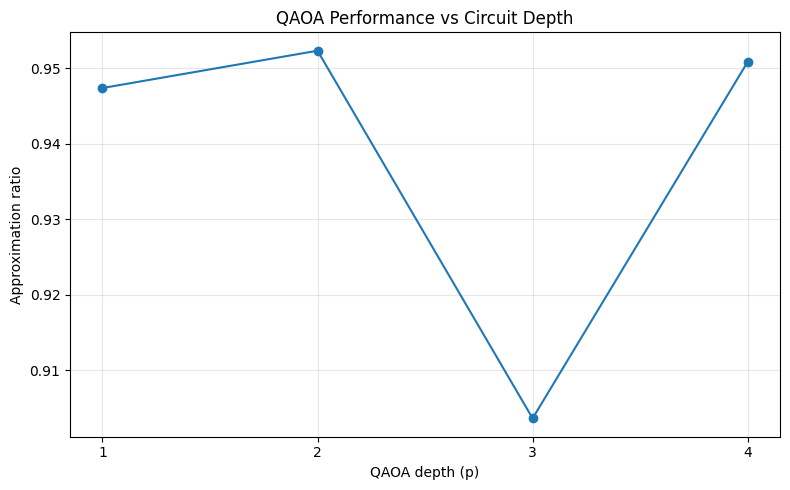

In [ ]:
# Step 5: QAOA approximation ratio for depths p = 1, 2, 3, 4

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import minimize
from qiskit.circuit.library import QAOAAnsatz
from qiskit.quantum_info import Statevector

# Use the same penalty strength as our validated Hamiltonian
lam = 1.0

# Calculate costs of all 2^6 = 64 bitstrings
all_bitstrings = [
    np.array([(i >> j) & 1 for j in range(n)])
    for i in range(2**n)
]

all_costs = np.array([
    portfolio_cost(x, lam=lam)
    for x in all_bitstrings
])

C_min = all_costs.min()
C_max = all_costs.max()

print(f"Minimum cost across all bitstrings: {C_min:.6f}")
print(f"Maximum cost across all bitstrings: {C_max:.6f}")

# Reproducible experiment
experiment_rng = np.random.default_rng(20261010)

depths = [1, 2, 3, 4]
records = []

for p in depths:
    print(f"\nRunning QAOA with depth p={p}...")

    ansatz = QAOAAnsatz(
        cost_operator=cost_hamiltonian,
        reps=p
    )

    parameters = list(ansatz.parameters)

    def expected_cost(theta):
        bound_circuit = ansatz.assign_parameters(
            dict(zip(parameters, theta))
        )

        state = Statevector.from_instruction(bound_circuit)

        return float(np.real(
            state.expectation_value(cost_hamiltonian)
        ))

    # Several starting points reduce dependence on initialization.
    best_result = None

    for restart in range(3):
        initial_point = experiment_rng.uniform(
            0, 2 * np.pi, len(parameters)
        )

        result = minimize(
            expected_cost,
            initial_point,
            method="COBYLA",
            options={"maxiter": 100, "tol": 1e-3}
        )

        if best_result is None or result.fun < best_result.fun:
            best_result = result

    E = float(best_result.fun)

    # Official challenge approximation-ratio definition
    ratio = (C_max - E) / (C_max - C_min)

    records.append({
        "depth": p,
        "expected_cost": E,
        "approximation_ratio": ratio
    })

    print(f"Best expected cost: {E:.6f}")
    print(f"Approximation ratio: {ratio:.6f}")


# Display the results
print("\nSummary")
print("-" * 53)

for row in records:
    print(
        f"p={row['depth']} | "
        f"Cost={row['expected_cost']:.6f} | "
        f"Ratio={row['approximation_ratio']:.6f}"
    )

# Required plot
plt.figure(figsize=(8, 5))

plt.plot(
    [row["depth"] for row in records],
    [row["approximation_ratio"] for row in records],
    marker="o"
)

plt.xticks(depths)
plt.xlabel("QAOA depth (p)")
plt.ylabel("Approximation ratio")
plt.title("QAOA Performance vs Circuit Depth")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Testing lambda = 0.05

Testing lambda = 0.1

Testing lambda = 0.2

Testing lambda = 0.5

Testing lambda = 1.0

Testing lambda = 2.0

Testing lambda = 5.0

PENALTY SWEEP RESULTS
----------------------------------------------------------------------------------------
 Lambda    Valid %     Best %  Mode valid?  Most sampled portfolio
   0.05     24.19%      2.00%        False  Stock 2, Stock 3, Stock 4, Stock 6
   0.10     47.00%      3.05%        False  Stock 2, Stock 3, Stock 4, Stock 6
   0.20     60.91%      3.56%         True  Stock 2, Stock 4, Stock 6
   0.50     66.11%      3.54%         True  Stock 1, Stock 2, Stock 5
   1.00     58.79%      3.93%         True  Stock 1, Stock 2, Stock 6
   2.00     67.58%      3.44%         True  Stock 2, Stock 3, Stock 5
   5.00     63.45%      2.25%         True  Stock 1, Stock 4, Stock 5


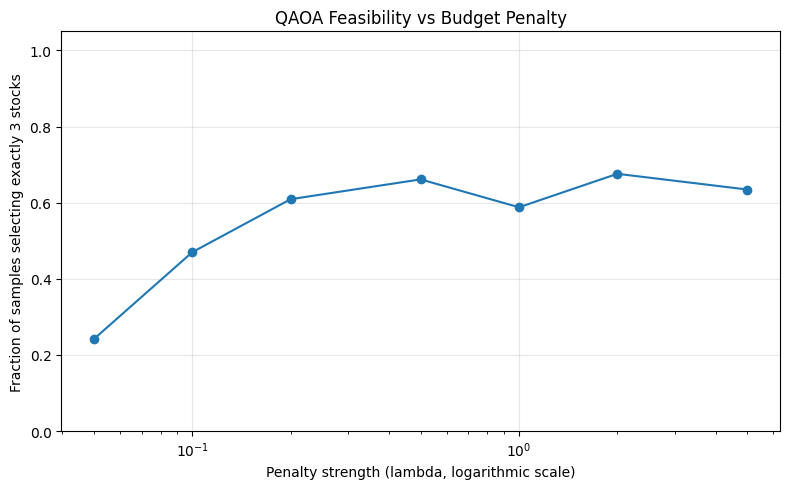

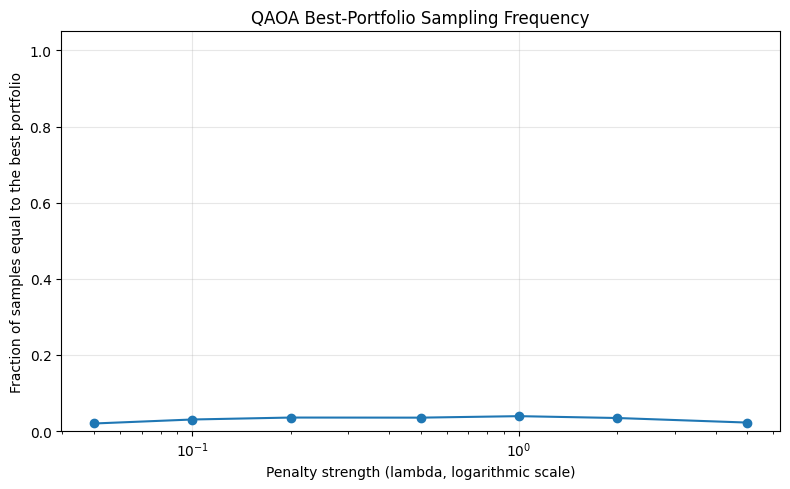

In [ ]:
# Step 6: Penalty-strength sweep

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import minimize
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.circuit.library import QAOAAnsatz

def build_portfolio_hamiltonian(lam):
    """Build the cost Hamiltonian for a given penalty strength."""

    linear = q * np.diag(sigma) - mu + lam * (1 - 2 * K)

    pair = {
        (i, j): 2 * q * sigma[i, j] + 2 * lam
        for i in range(n)
        for j in range(i + 1, n)
    }

    constant = (
        lam * K**2
        + 0.5 * np.sum(linear)
        + 0.25 * sum(pair.values())
    )

    terms = [("I" * n, constant)]

    # Single-qubit Z terms
    for i in range(n):
        z_coefficient = (
            -0.5 * linear[i]
            - 0.25 * sum(
                value for (a, b), value in pair.items()
                if i == a or i == b
            )
        )

        label = ["I"] * n
        label[n - 1 - i] = "Z"
        terms.append(("".join(label), z_coefficient))

    # Two-qubit ZZ terms
    for (i, j), coefficient in pair.items():
        label = ["I"] * n
        label[n - 1 - i] = "Z"
        label[n - 1 - j] = "Z"
        terms.append(("".join(label), coefficient / 4))

    return SparsePauliOp.from_list(terms).simplify()


# Penalty values to investigate
lambda_values = [0.05, 0.1, 0.2, 0.5, 1.0, 2.0, 5.0]

p_sweep = 1
shots = 4096
rng_sweep = np.random.default_rng(20261010)

# Index of the known best valid portfolio in Qiskit's bit ordering
best_index = sum(int(best_x[i]) << i for i in range(n))

records = []

for lam_value in lambda_values:
    print(f"\nTesting lambda = {lam_value}")

    H = build_portfolio_hamiltonian(lam_value)
    ansatz = QAOAAnsatz(cost_operator=H, reps=p_sweep)
    params = list(ansatz.parameters)

    def objective(theta):
        bound = ansatz.assign_parameters(dict(zip(params, theta)))
        state = Statevector.from_instruction(bound)
        return float(np.real(state.expectation_value(H)))

    # Multiple starting points reduce sensitivity to initialization.
    best_result = None

    for restart in range(3):
        initial = rng_sweep.uniform(0, 2 * np.pi, len(params))

        result = minimize(
            objective,
            initial,
            method="COBYLA",
            options={"maxiter": 100, "tol": 1e-3}
        )

        if best_result is None or result.fun < best_result.fun:
            best_result = result

    optimized = ansatz.assign_parameters(
        dict(zip(params, best_result.x))
    )

    state = Statevector.from_instruction(optimized)
    probabilities = np.abs(state.data) ** 2
    probabilities /= probabilities.sum()

    counts = rng_sweep.multinomial(shots, probabilities)

    def decode(index):
        return np.array(
            [(index >> i) & 1 for i in range(n)],
            dtype=int
        )

    valid_count = sum(
        counts[i] for i in range(2**n)
        if decode(i).sum() == K
    )

    best_count = int(counts[best_index])

    most_sampled_index = int(np.argmax(counts))
    most_sampled_portfolio = decode(most_sampled_index)
    modal_valid = (most_sampled_portfolio.sum() == K)

    selected = [
        f"Stock {i + 1}"
        for i, bit in enumerate(most_sampled_portfolio)
        if bit
    ]

    record = {
        "lambda": lam_value,
        "valid_fraction": valid_count / shots,
        "best_fraction": best_count / shots,
        "modal_valid": modal_valid,
        "modal_portfolio": ", ".join(selected),
        "expected_cost": float(best_result.fun)
    }

    records.append(record)

# Report all measurements
print("\nPENALTY SWEEP RESULTS")
print("-" * 88)
print(
    f"{'Lambda':>7} {'Valid %':>10} {'Best %':>10} "
    f"{'Mode valid?':>12}  Most sampled portfolio"
)

for r in records:
    print(
        f"{r['lambda']:7.2f} "
        f"{100*r['valid_fraction']:9.2f}% "
        f"{100*r['best_fraction']:9.2f}% "
        f"{str(r['modal_valid']):>12}  "
        f"{r['modal_portfolio']}"
    )

# Required plot: fraction of valid portfolios against penalty strength
plt.figure(figsize=(8, 5))
plt.plot(
    [r["lambda"] for r in records],
    [r["valid_fraction"] for r in records],
    marker="o"
)
plt.xscale("log")
plt.ylim(0, 1.05)
plt.xlabel("Penalty strength (lambda, logarithmic scale)")
plt.ylabel("Fraction of samples selecting exactly 3 stocks")
plt.title("QAOA Feasibility vs Budget Penalty")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Additional analysis: probability of sampling the best portfolio
plt.figure(figsize=(8, 5))
plt.plot(
    [r["lambda"] for r in records],
    [r["best_fraction"] for r in records],
    marker="o"
)
plt.xscale("log")
plt.ylim(0, 1.05)
plt.xlabel("Penalty strength (lambda, logarithmic scale)")
plt.ylabel("Fraction of samples equal to the best portfolio")
plt.title("QAOA Best-Portfolio Sampling Frequency")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Final QAOA vs. classical comparison

In [ ]:
# Step 7: Final evaluation — QAOA vs Classical Optimum

import numpy as np
from itertools import combinations
from scipy.optimize import minimize
from qiskit.circuit.library import QAOAAnsatz
from qiskit.quantum_info import Statevector

# Experiment settings
lam_eval = 1.0
p_eval = 1
shots_eval = 4096

# 1. Find the exact best VALID portfolio classically
valid_candidates = []

for chosen in combinations(range(n), K):
    x = np.zeros(n, dtype=int)
    x[list(chosen)] = 1
    valid_candidates.append((x, portfolio_cost(x, lam=lam_eval)))

classical_best_x, classical_best_cost = min(
    valid_candidates,
    key=lambda item: item[1]
)

# 2. Build the QAOA circuit for the same objective
H_eval = build_portfolio_hamiltonian(lam_eval)

ansatz_eval = QAOAAnsatz(
    cost_operator=H_eval,
    reps=p_eval
)

params_eval = list(ansatz_eval.parameters)
rng_eval = np.random.default_rng(20261011)

def expected_cost_eval(theta):
    bound = ansatz_eval.assign_parameters(
        dict(zip(params_eval, theta))
    )
    state = Statevector.from_instruction(bound)
    return float(np.real(state.expectation_value(H_eval)))

# Multiple restarts help reduce initialization sensitivity
best_result_eval = None

for restart in range(5):
    initial = rng_eval.uniform(
        0, 2 * np.pi, len(params_eval)
    )

    result = minimize(
        expected_cost_eval,
        initial,
        method="COBYLA",
        options={"maxiter": 150, "tol": 1e-3}
    )

    if (
        best_result_eval is None
        or result.fun < best_result_eval.fun
    ):
        best_result_eval = result

optimized_eval = ansatz_eval.assign_parameters(
    dict(zip(params_eval, best_result_eval.x))
)

# 3. Simulate measurements
state_eval = Statevector.from_instruction(optimized_eval)
probabilities_eval = np.abs(state_eval.data) ** 2
probabilities_eval /= probabilities_eval.sum()

counts_eval = rng_eval.multinomial(
    shots_eval, probabilities_eval
)

def decode_eval(index):
    return np.array(
        [(index >> i) & 1 for i in range(n)],
        dtype=int
    )

# 4. Find the best valid portfolio actually observed
valid_observed = []

for index, count in enumerate(counts_eval):
    if count == 0:
        continue

    x = decode_eval(index)

    if x.sum() == K:
        valid_observed.append(
            (x, portfolio_cost(x, lam=lam_eval), int(count))
        )

if not valid_observed:
    raise RuntimeError(
        "No valid portfolios were observed. "
        "Try more shots or another QAOA initialization."
    )

qaoa_best_x, qaoa_best_cost, qaoa_best_count = min(
    valid_observed,
    key=lambda item: item[1]
)

# 5. Calculate the gap against the exact valid optimum
cost_gap = qaoa_best_cost - classical_best_cost

relative_gap_pct = (
    100 * cost_gap / abs(classical_best_cost)
    if abs(classical_best_cost) > 1e-12
    else float("nan")
)

valid_shots_eval = sum(
    int(counts_eval[i])
    for i in range(2**n)
    if decode_eval(i).sum() == K
)

classical_best_index = sum(
    int(classical_best_x[i]) << i for i in range(n)
)

best_solution_hits = int(counts_eval[classical_best_index])

def stock_names(x):
    return [
        f"Stock {i + 1}"
        for i, selected in enumerate(x)
        if selected
    ]

# 6. Print the final report
print("=" * 58)
print("FINAL QAOA PORTFOLIO EVALUATION")
print("=" * 58)

print("\nClassical optimum:")
print("Selected:", stock_names(classical_best_x))
print(f"Cost: {classical_best_cost:.6f}")

print("\nBest valid portfolio observed by QAOA:")
print("Selected:", stock_names(qaoa_best_x))
print(f"Cost: {qaoa_best_cost:.6f}")
print(f"Occurrences: {qaoa_best_count} / {shots_eval}")

print("\nPerformance:")
print(f"Total shots: {shots_eval}")
print(
    f"Valid portfolios: {valid_shots_eval} "
    f"({valid_shots_eval / shots_eval:.2%})"
)
print(
    f"Exact classical optimum observed: "
    f"{best_solution_hits} times "
    f"({best_solution_hits / shots_eval:.2%})"
)
print(f"Absolute cost gap: {cost_gap:.6f}")
print(f"Relative cost gap: {relative_gap_pct:.2f}%")

if np.array_equal(qaoa_best_x, classical_best_x):
    print("\nResult: QAOA sampled the exact classical optimum.")
else:
    print("\nResult: QAOA found a valid portfolio, but did not "
          "sample the exact optimum as its best observed solution.")

print("\nNote: QAOA is probabilistic; results depend on")
print("initialization, optimization, circuit depth, and sampling.")

FINAL QAOA PORTFOLIO EVALUATION

Classical optimum:
Selected: ['Stock 2', 'Stock 3', 'Stock 6']
Cost: -0.503015

Best valid portfolio observed by QAOA:
Selected: ['Stock 2', 'Stock 3', 'Stock 6']
Cost: -0.503015
Occurrences: 147 / 4096

Performance:
Total shots: 4096
Valid portfolios: 2780 (67.87%)
Exact classical optimum observed: 147 times (3.59%)
Absolute cost gap: 0.000000
Relative cost gap: 0.00%

Result: QAOA sampled the exact classical optimum.

Note: QAOA is probabilistic; results depend on
initialization, optimization, circuit depth, and sampling.


In [ ]:
required = ["n", "K", "q", "mu", "sigma", "portfolio_cost"]

for name in required:
    print(f"{name}: {'Available' if name in globals() else 'Missing'}")

n: Available
K: Available
q: Available
mu: Available
sigma: Available
portfolio_cost: Available


In [ ]:
from google.colab import userdata
from qiskit_ibm_runtime import QiskitRuntimeService

api_key = userdata.get("IBM_QUANTUM_API_KEY")

service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    token=api_key
)

backend = service.backend("ibm_kingston")

print("Connected to IBM Quantum")
print("Backend:", backend.name)
print("Qubits:", backend.num_qubits)
print("Operational:", backend.status().operational)

# Inspect the saved optimization variables
print("\nPotential optimization-result variables:")
for name, value in list(globals().items()):
    if any(word in name.lower() for word in ["param", "theta", "result", "opt"]):
        if hasattr(value, "x"):
            print(name, "->", getattr(value, "x"))
        elif name.lower() in ["best_params", "optimized_params", "optimal_params"]:
            print(name, "->", value)

qiskit_runtime_service._discover_account:WARNING:2026-10-14 11:39:16,833: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-10-14 11:39:19,364: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-10-14 11:39:19,365: Using instance: open-instance, plan: open


Connected to IBM Quantum
Backend: ibm_kingston
Qubits: 156
Operational: True

Potential optimization-result variables:
result -> [8.06693392 3.55740758]
best_qaoa_result -> [1.32003404 0.36022213]
optimized_circuit -> <bound method QuantumCircuit.x of <qiskit.circuit.library.n_local.qaoa_ansatz.QAOAAnsatz object at 0x7a183bd32990>>
best_result -> [6.04570491 1.80796924]
optimized -> <bound method QuantumCircuit.x of <qiskit.circuit.library.n_local.qaoa_ansatz.QAOAAnsatz object at 0x7a183972da90>>
best_result_eval -> [2.88890131 0.36035966]
optimized_eval -> <bound method QuantumCircuit.x of <qiskit.circuit.library.n_local.qaoa_ansatz.QAOAAnsatz object at 0x7a18395de0d0>>


## Circiut preperation for IBM Quantum Hardware

In [ ]:
from qiskit import transpile

# 1. Get the optimized values from the optimization result
optimized_values = best_qaoa_result.x

# 2. Get parameters from the actual six-qubit circuit
circuit_parameters = list(qaoa_ansatz.parameters)

print("Circuit qubits:", qaoa_ansatz.num_qubits)
print("Circuit parameters:", circuit_parameters)
print("Optimized values:", optimized_values)

# 3. Verify that the parameter counts match
assert len(circuit_parameters) == len(optimized_values), (
    f"Mismatch: circuit has {len(circuit_parameters)} parameters, "
    f"but optimizer returned {len(optimized_values)} values."
)

# 4. Bind parameters to this circuit only
binding = dict(zip(circuit_parameters, optimized_values))
qaoa_bound = qaoa_ansatz.assign_parameters(binding)

# 5. Add measurements and compile for IBM hardware
qaoa_hardware = qaoa_bound.copy()
qaoa_hardware.measure_all()

qaoa_isa = transpile(
    qaoa_hardware,
    backend=backend,
    optimization_level=1
)

print("\nCircuit preparation successful.")
print("Backend:", backend.name)
print("Remaining parameters:", qaoa_isa.num_parameters)
print("Compiled circuit depth:", qaoa_isa.depth())

Circuit qubits: 6
Circuit parameters: [ParameterVectorElement(β[0]), ParameterVectorElement(γ[0])]
Optimized values: [1.32003404 0.36022213]

Circuit preparation successful.
Backend: ibm_kingston
Remaining parameters: 0
Compiled circuit depth: 141


## IBM Quantum Hardware Evaluation

The notebook demonstrates real quantum-hardware execution using IBM Quantum Runtime.

The portfolio QAOA experiment was executed on the `ibm_kingston` backend using 1,024 shots. The returned counts are decoded and checked against the requirement to select exactly three stocks. The analysis records the valid-sample rate, the frequency of the exact classical optimum, and the cost of the best valid portfolio.

The recorded hardware evaluation found 609 valid samples out of 1,024, and the exact classical optimum appeared 29 times. The best valid portfolio matched Stock 2, Stock 3, and Stock 6, with an objective cost of −0.503015.

The notebook also contains a separate Bell-state hardware demonstration. These experiments illustrate basic quantum-circuit execution and a small optimization workflow; the Bell experiment is not part of the portfolio optimization algorithm.

Real hardware results can differ from simulator results because of device noise, imperfect gates, and measurement errors. These experiments do not establish quantum advantage over classical optimization.

In [ ]:
# Current IBM Quantum Sampler interface
from qiskit_ibm_runtime.executor_sampler import Sampler

# Confirm we're submitting the prepared circuit
assert qaoa_isa.num_parameters == 0
assert backend.status().operational

print("Submitting portfolio QAOA to real hardware...")
print("Backend:", backend.name)
print("Shots:", 1024)
print("Circuit depth:", qaoa_isa.depth())

# Submit the circuit to IBM quantum hardware
sampler = Sampler(mode=backend)
job = sampler.run([qaoa_isa], shots=1024)

# Save the job ID as evidence for your project
hardware_job_id = job.job_id()
print("\nHardware job ID:", hardware_job_id)
print("Job status:", job.status())

# Wait for the result
hardware_result = job.result()
hardware_counts = hardware_result[0].data.meas.get_counts()

print("\nHardware measurement counts:")
print(hardware_counts)
print("Total measurement shots:", sum(hardware_counts.values()))

qiskit_runtime_service.backends:WARNING:2026-10-14 11:42:59,264: Using instance: open-instance, plan: open


Submitting portfolio QAOA to real hardware...
Backend: ibm_kingston
Shots: 1024
Circuit depth: 141

Hardware job ID: db7mlh0r1c5c738kspdg
Job status: QUEUED

Hardware measurement counts:
{'101111': 3, '001100': 10, '011001': 37, '010011': 41, '101100': 23, '100111': 16, '001011': 26, '000011': 15, '001101': 35, '001110': 28, '110100': 18, '011010': 33, '100100': 12, '000110': 9, '011100': 22, '100110': 29, '001001': 8, '010110': 37, '000111': 32, '111010': 19, '110010': 31, '010111': 31, '100011': 36, '111100': 10, '101001': 34, '000000': 3, '101010': 20, '010010': 7, '100010': 9, '101110': 13, '010101': 36, '011101': 23, '110101': 13, '100001': 8, '011110': 22, '110001': 27, '100101': 38, '011000': 2, '010100': 8, '101011': 13, '111110': 1, '111000': 26, '000101': 9, '001010': 11, '100000': 3, '111001': 13, '101000': 12, '101101': 12, '011011': 26, '110000': 4, '111011': 2, '001111': 15, '110110': 10, '110011': 11, '010001': 18, '010000': 2, '000010': 2, '001000': 3, '011111': 1, '000

In [ ]:
from collections import Counter
import numpy as np

# Use the existing hardware measurement counts
counts = hardware_counts

# The original portfolio setup
assert n == 6 and K == 3

portfolio_results = []
valid_count = 0
best_hardware_cost = float("inf")
best_hardware_portfolio = None

for bitstring, count in counts.items():
    # Qiskit count strings display classical bit c[n-1] first.
    # Reverse to restore the original qubit order.
    x = np.array([int(bit) for bit in bitstring[::-1]], dtype=int)

    selected = np.where(x == 1)[0]
    is_valid = len(selected) == K
    cost = portfolio_cost(x, lam=1.0)

    if is_valid:
        valid_count += count
        if cost < best_hardware_cost:
            best_hardware_cost = cost
            best_hardware_portfolio = selected.tolist()

    portfolio_results.append({
        "bitstring": bitstring,
        "count": count,
        "selected_stocks": [f"Stock {i+1}" for i in selected],
        "valid": is_valid,
        "cost": cost,
    })

# Classical reference from the existing notebook
print("IBM QAOA HARDWARE EVALUATION")
print("=" * 45)
print("Job ID:", hardware_job_id)
print("Backend:", backend.name)
print("Total shots:", sum(counts.values()))
print(f"Valid shots: {valid_count} ({valid_count / sum(counts.values()) * 100:.2f}%)")

print("\nBest valid portfolio observed on hardware:")
if best_hardware_portfolio is not None:
    print([f"Stock {i+1}" for i in best_hardware_portfolio])
    print(f"Portfolio cost: {best_hardware_cost:.6f}")
else:
    print("No valid portfolio was observed.")

print("\nMost frequently measured bitstrings:")
for item in sorted(portfolio_results, key=lambda r: r["count"], reverse=True)[:10]:
    print(
        item["bitstring"],
        "| Count:", item["count"],
        "| Valid:", item["valid"],
        "| Cost:", f"{item['cost']:.6f}"
    )

IBM QAOA HARDWARE EVALUATION
Job ID: db7mlh0r1c5c738kspdg
Backend: ibm_kingston
Total shots: 1024
Valid shots: 609 (59.47%)

Best valid portfolio observed on hardware:
['Stock 2', 'Stock 3', 'Stock 6']
Portfolio cost: -0.503015

Most frequently measured bitstrings:
010011 | Count: 41 | Valid: True | Cost: -0.340510
100101 | Count: 38 | Valid: True | Cost: -0.409479
011001 | Count: 37 | Valid: True | Cost: -0.221971
010110 | Count: 37 | Valid: True | Cost: -0.407299
100011 | Count: 36 | Valid: True | Cost: -0.464474
010101 | Count: 36 | Valid: True | Cost: -0.318189
001101 | Count: 35 | Valid: True | Cost: -0.319628
101001 | Count: 34 | Valid: True | Cost: -0.382259
011010 | Count: 33 | Valid: True | Cost: -0.313996
000111 | Count: 32 | Valid: True | Cost: -0.393170


In [ ]:
# Count how often the exact optimal portfolio was measured
optimal_stocks = {2, 3, 6}
optimal_count = 0

for bitstring, count in hardware_counts.items():
    x = [int(bit) for bit in bitstring[::-1]]
    selected_stocks = {
        i + 1 for i, bit in enumerate(x) if bit == 1
    }

    if selected_stocks == optimal_stocks:
        optimal_count += count

total_shots = sum(hardware_counts.values())

print("EXACT OPTIMUM FREQUENCY")
print("=" * 35)
print("Optimal portfolio: Stock 2, Stock 3, Stock 6")
print("Optimal measurements:", optimal_count)
print("Total shots:", total_shots)
print(f"Optimal sampling probability: {optimal_count / total_shots:.2%}")
print("Optimal portfolio cost: -0.503015")
print("Hardware job ID:", hardware_job_id)

EXACT OPTIMUM FREQUENCY
Optimal portfolio: Stock 2, Stock 3, Stock 6
Optimal measurements: 29
Total shots: 1024
Optimal sampling probability: 2.83%
Optimal portfolio cost: -0.503015
Hardware job ID: db7mlh0r1c5c738kspdg


### Real Quantum Hardware Evaluation — Beginner QAOA

**Platform:** IBM Quantum  
**Backend:** `ibm_kingston`  
**Hardware job ID:** `db7mlh0r1c5c738kspdg`  
**Circuit:** 6-qubit QAOA, depth \(p=1\)  
**Measurement shots:** 1,024

**Results**
- Valid portfolios selecting exactly three stocks: 609/1,024 (59.47%).
- Exact classical-optimal portfolio observed: 29/1,024 (2.83%).
- Best observed portfolio: Stock 2, Stock 3, Stock 6.
- Best observed objective cost: −0.503015.
- Classical optimum objective cost: −0.503015.
- Absolute cost gap: 0.000000.

**Interpretation:** The real quantum processor sampled the exact classical-optimal portfolio. The hardware's valid-portfolio rate was 59.47%, and the optimal portfolio appeared in 2.83% of measurements. These results demonstrate successful execution of the QAOA circuit on real quantum hardware, but do not establish quantum advantage. The experiment uses a small problem, a single hardware run, and a classical reference solution.

**Limitations:** Hardware noise, circuit compilation, sampling variability, and the limited optimization budget may affect performance. A rigorous quantum-advantage claim would require broader repeated comparisons and a fair accounting of classical and quantum computational costs.